# ELEC6604 作业 3 — 依次运行 CNN_A、CNN_B、CNN_C

在 Colab 中启用 GPU，然后从上到下运行，或选择“全部运行”。无需切换模型。
流程：共享配置和数据 → 定义模型及实验函数 → CNN_A → CNN_B → CNN_C → 汇总与下载。
每个模型使用三个随机种子、每次 30 轮，共九次训练。所有模型使用相同数据划分和训练配置。
快速检查可将 `SEEDS = [42]`、`EPOCHS = 1`，正式实验请恢复默认值。
此版本已清空旧输出，避免把旧 CNN_C 结果误认为本次三模型结果；原有运行记录另存为备份 Notebook。


In [9]:
import os
import json
import time
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    print("No GPU detected. Enable a GPU runtime in Colab for faster training.")


TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. 共享实验配置
三个模型共用数据划分、随机种子、训练轮数、批次大小、学习率和归一化方式。
`NORMALIZATION` 可设为 `zero_one`（[0,1]）或 `minus_one_one`（[-1,1]），用于后续归一化对照实验。
启用 `SAVE_TO_DRIVE` 可持久保存结果；否则结束 Colab 会话前请下载最终 ZIP。
每次重新运行配置单元格都会创建新的实验目录并重置汇总记录。中断后若运行时仍在，可直接重跑未完成模型的单元格，无需重跑配置和已完成模型。


In [10]:
SEEDS = [42, 123, 2026]
SPLIT_SEED = 2026
EPOCHS = 30
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
C_L2 = 1e-4
C_BLOCK_DROPOUT = (0.2, 0.3, 0.4)
C_DENSE_DROPOUT = 0.5
NORMALIZATION = "zero_one"
SAVE_TO_DRIVE = False

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_ROOT = Path("/content/drive/MyDrive/ELEC6604_Assignment3")
else:
    OUTPUT_ROOT = Path("/content/assignment3_results")

RUN_ID = time.strftime("%Y%m%d-%H%M%S")
EXPERIMENT_DIR = OUTPUT_ROOT / f"CNN_ABC_{NORMALIZATION}_{RUN_ID}"
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
assert NORMALIZATION in {"zero_one", "minus_one_one"}
assert EPOCHS > 0 and len(SEEDS) == len(set(SEEDS)) and len(SEEDS) > 0
try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError) as exc:
    print("Deterministic operations could not be enabled:", exc)
print("Results directory:", EXPERIMENT_DIR)

all_results = {}
all_summaries = {}


Results directory: /content/assignment3_results/CNN_ABC_zero_one_20261118-220529


## 2. 加载与预处理 CIFAR-10
通过 Keras 直接下载数据，无需手动上传 CIFAR 批次文件。
按类别分层抽样，将原始 50,000 张训练图片划分为 45,000 张训练图片和 5,000 张验证图片。官方 10,000 张测试图片独立保留。
将像素转为 float32 并归一化；将类别标签转为独热编码（one-hot），用于分类交叉熵损失。


In [11]:
(images, labels), (test_images, test_labels) = keras.datasets.cifar10.load_data()
train_indices, val_indices = train_test_split(
    np.arange(len(images)), test_size=0.1, random_state=SPLIT_SEED,
    stratify=labels.ravel(),
)

def normalize(x):
    x = x.astype("float32") / 255.0
    return (x - 0.5) * 2.0 if NORMALIZATION == "minus_one_one" else x

X_train = normalize(images[train_indices])
X_val = normalize(images[val_indices])
X_test = normalize(test_images)
Y_train = keras.utils.to_categorical(labels[train_indices], 10)
Y_val = keras.utils.to_categorical(labels[val_indices], 10)
Y_test = keras.utils.to_categorical(test_labels, 10)
np.savez(EXPERIMENT_DIR / "split_indices.npz", train=train_indices, validation=val_indices)
del images, test_images
for name, x, y in [("Train", X_train, Y_train), ("Validation", X_val, Y_val), ("Test", X_test, Y_test)]:
    print(name, "images:", x.shape, "labels:", y.shape, "range:", (x.min(), x.max()))
assert (len(X_train), len(X_val), len(X_test)) == (45000, 5000, 10000)
assert not np.intersect1d(train_indices, val_indices).size


Train images: (45000, 32, 32, 3) labels: (45000, 10) range: (np.float32(0.0), np.float32(1.0))
Validation images: (5000, 32, 32, 3) labels: (5000, 10) range: (np.float32(0.0), np.float32(1.0))
Test images: (10000, 32, 32, 3) labels: (10000, 10) range: (np.float32(0.0), np.float32(1.0))


## 3. 模型结构
### CNN_A
`32×32×3 → Conv32 → Pool → Conv64 → Pool → Conv128 → Pool → Flatten → Dense128 → Softmax10`

卷积核均为 3×3，使用 same 填充和 ReLU；最大池化窗口为 2×2。
不使用 Dropout、批归一化、权重衰减、数据增强或标签平滑。
参数量：896 + 18,496 + 73,856 + 262,272 + 1,290 = **356,810**，满足 20万～70万要求。

### CNN_B
`32×32×3 → Conv64 → Conv64 → Pool → Conv128 → Conv128 → Pool → Conv256 → Conv256 → Pool → Flatten4096 → Dense2048 → Dense1024 → Softmax10`

比 CNN_A 更宽、更深：六个卷积层和两个较大的全连接隐藏层。卷积核均为 3×3，使用 same 填充和 ReLU；最大池化窗口为 2×2，不使用正则化。
参数量：卷积层 1,145,408 + Dense2048 8,390,656 + Dense1024 2,098,176 + 分类输出层 10,250 = **11,644,490**，满足 1000万～1500万要求。
较大的模型容量可能导致过拟合，需要根据完整曲线判断。相比 CNN_A，CNN_B 需要更多训练时间和 GPU 显存。

### CNN_C
`输入 → [Conv32–BN–ReLU]×2 → Pool → Dropout0.2 → [Conv64–BN–ReLU]×2 → Pool → Dropout0.3 → [Conv128–BN–ReLU]×2 → Pool → Dropout0.4 → Flatten2048 → Dense512–BN–ReLU → Dropout0.5 → Softmax10`

卷积滤波器数为 CNN_B 的一半，将 B 的 2048／1024 节点全连接隐藏层替换为单个 512 节点隐藏层。
使用 L2 核权重正则化（默认系数 0.0001）、批归一化（BN）和 Dropout 来减少过拟合，效果需通过验证结果确认。不使用数据增强或标签平滑。
卷积核为 3×3，使用 same 填充；最大池化窗口为 2×2。紧接 BN 的层不使用偏置，因为 BN 已包含可学习的偏移量。

参数计算公式：无偏置卷积层 = 核高 × 核宽 × 输入通道数 × 输出通道数；无偏置全连接层 = 输入数 × 输出数；BN = 4 × 通道数（缩放、偏移、移动均值和移动方差）；输出全连接层 =（输入数 + 1）× 输出数。

| 层名称 | 参数量 |
|---|---:|
| conv1 | 864 |
| bn1 | 128 |
| conv2 | 9,216 |
| bn2 | 128 |
| conv3 | 18,432 |
| bn3 | 256 |
| conv4 | 36,864 |
| bn4 | 256 |
| conv5 | 73,728 |
| bn5 | 512 |
| conv6 | 147,456 |
| bn6 | 512 |
| dense1 | 1,048,576 |
| bn_dense | 2,048 |
| class_probabilities | 5,130 |

总参数量 **1,344,106** = **1,342,186 个可训练参数** + **1,920 个不可训练参数**，满足 100万～500万要求。
ReLU、池化、展平和 Dropout 均无参数。下一个单元格逐层核对手算值与 Keras 结果，并导出表格。

**损失解读：** CNN_C 的损失包含 L2 惩罚项，不能直接与 A／B 的无正则交叉熵比较大小；准确率可以比较。Dropout 和 BN 在训练与评价时的行为不同，应结合最终推理模式下的指标及训练曲线分析泛化差距。


In [12]:
def build_cnn_a():
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1"),
        layers.MaxPooling2D(2, name="pool1"),
        layers.Conv2D(64, 3, padding="same", activation="relu", name="conv2"),
        layers.MaxPooling2D(2, name="pool2"),
        layers.Conv2D(128, 3, padding="same", activation="relu", name="conv3"),
        layers.MaxPooling2D(2, name="pool3"),
        layers.Flatten(name="flatten"),
        layers.Dense(128, activation="relu", name="dense1"),
        layers.Dense(10, activation="softmax", name="class_probabilities"),
    ], name="CNN_A")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="categorical_crossentropy", metrics=["accuracy"],
    )
    return model

def build_cnn_b():
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(64, 3, padding="same", activation="relu", name="conv1"),
        layers.Conv2D(64, 3, padding="same", activation="relu", name="conv2"),
        layers.MaxPooling2D(2, name="pool1"),
        layers.Conv2D(128, 3, padding="same", activation="relu", name="conv3"),
        layers.Conv2D(128, 3, padding="same", activation="relu", name="conv4"),
        layers.MaxPooling2D(2, name="pool2"),
        layers.Conv2D(256, 3, padding="same", activation="relu", name="conv5"),
        layers.Conv2D(256, 3, padding="same", activation="relu", name="conv6"),
        layers.MaxPooling2D(2, name="pool3"),
        layers.Flatten(name="flatten"),
        layers.Dense(2048, activation="relu", name="dense1"),
        layers.Dense(1024, activation="relu", name="dense2"),
        layers.Dense(10, activation="softmax", name="class_probabilities"),
    ], name="CNN_B")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="categorical_crossentropy", metrics=["accuracy"],
    )
    return model

def build_cnn_c():
    model = keras.Sequential(name="CNN_C")
    model.add(layers.Input(shape=(32, 32, 3)))
    conv_id = 0
    for block, (filters, rate) in enumerate(zip((32, 64, 128), C_BLOCK_DROPOUT), 1):
        for _ in range(2):
            conv_id += 1
            model.add(layers.Conv2D(
                filters, 3, padding="same", use_bias=False,
                kernel_regularizer=keras.regularizers.l2(C_L2), name=f"conv{conv_id}",
            ))
            model.add(layers.BatchNormalization(name=f"bn{conv_id}"))
            model.add(layers.Activation("relu", name=f"relu{conv_id}"))
        model.add(layers.MaxPooling2D(2, name=f"pool{block}"))
        model.add(layers.Dropout(rate, name=f"dropout{block}"))
    model.add(layers.Flatten(name="flatten"))
    model.add(layers.Dense(512, use_bias=False, kernel_regularizer=keras.regularizers.l2(C_L2), name="dense1"))
    model.add(layers.BatchNormalization(name="bn_dense"))
    model.add(layers.Activation("relu", name="relu_dense"))
    model.add(layers.Dropout(C_DENSE_DROPOUT, name="dropout_dense"))
    model.add(layers.Dense(10, activation="softmax", kernel_regularizer=keras.regularizers.l2(C_L2), name="class_probabilities"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="categorical_crossentropy", metrics=["accuracy"],
    )
    return model

MODEL_BUILDERS = {"CNN_A": build_cnn_a, "CNN_B": build_cnn_b, "CNN_C": build_cnn_c}
EXPECTED_PARAMETERS = {"CNN_A": 356810, "CNN_B": 11644490, "CNN_C": 1344106}
PARAMETER_LIMITS = {"CNN_A": (200_000, 700_000), "CNN_B": (10_000_000, 15_000_000), "CNN_C": (1_000_000, 5_000_000)}

def build_model(model_name):
    model = MODEL_BUILDERS[model_name]()
    lower, upper = PARAMETER_LIMITS[model_name]
    assert lower <= model.count_params() <= upper
    assert model.count_params() == EXPECTED_PARAMETERS[model_name]
    if model_name != "CNN_C":
        assert not model.losses, "CNN_A and CNN_B must not have regularization losses."
    return model

assert len(C_BLOCK_DROPOUT) == 3 and all(0 <= r < 1 for r in C_BLOCK_DROPOUT)
assert 0 <= C_DENSE_DROPOUT < 1 and C_L2 >= 0


## 4. 共用的模型说明、训练和评估函数
以下单元格定义函数，不会开始训练。每个模型均使用验证损失最低的权重进行最终评价，不使用测试集选择权重。
每次完成全部训练轮数，不使用提前停止；计时包含验证和权重保存，不含数据下载及最终评估。
曲线记录训练模式下的指标；结果表是在选中权重后，以推理模式重新评价的数据。
每个模型分别保存参数概要、结构图、逐轮日志、权重、三种子结果、均值与标准差、曲线和 ZIP。CNN_C 额外保存逐层参数核对表。


In [13]:
def save_model_description(model_name, output_dir):
    preview_model = build_model(model_name)
    if model_name == "CNN_C":
        manual_counts = {'conv1': 864, 'bn1': 128, 'conv2': 9216, 'bn2': 128, 'conv3': 18432, 'bn3': 256, 'conv4': 36864, 'bn4': 256, 'conv5': 73728, 'bn5': 512, 'conv6': 147456, 'bn6': 512, 'dense1': 1048576, 'bn_dense': 2048, 'class_probabilities': 5130}
        parameter_rows = []
        for layer in preview_model.layers:
            expected = manual_counts.get(layer.name, 0)
            actual = layer.count_params()
            assert actual == expected, (layer.name, expected, actual)
            parameter_rows.append({"layer": layer.name, "manual_parameters": expected, "keras_parameters": actual})
        assert sum(manual_counts.values()) == preview_model.count_params()
        parameter_table = pd.DataFrame(parameter_rows)
        parameter_table.to_csv(output_dir / "CNN_C_parameter_calculation.csv", index=False)
        display(parameter_table)

    preview_model.summary()
    summary_lines = []
    preview_model.summary(print_fn=lambda line: summary_lines.append(line))
    (output_dir / "model_summary.txt").write_text("\n".join(summary_lines))
    try:
        keras.utils.plot_model(preview_model, to_file=str(output_dir / f"{model_name}_architecture.png"), show_shapes=True)
    except (ImportError, OSError) as exc:
        print("Optional architecture image unavailable:", exc)
    del preview_model


def run_experiment(model_name):
    # 各模型使用独立目录，避免指标和权重混在一起。
    output_dir = EXPERIMENT_DIR / model_name
    output_dir.mkdir(parents=True, exist_ok=True)
    keras.backend.clear_session()
    save_model_description(model_name, output_dir)
    np.savez(output_dir / "split_indices.npz", train=train_indices, validation=val_indices)
    config = {
        "model": model_name, "seeds": SEEDS, "split_seed": SPLIT_SEED,
        "epochs": EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
        "normalization": NORMALIZATION, "tensorflow_version": tf.__version__,
        "devices": [str(d) for d in tf.config.list_physical_devices()],
        "regularization": {"l2": C_L2, "block_dropout": C_BLOCK_DROPOUT, "dense_dropout": C_DENSE_DROPOUT, "batch_normalization": True} if model_name == "CNN_C" else None,
        "checkpoint_selection": "minimum validation loss",
    }
    (output_dir / "config.json").write_text(json.dumps(config, indent=2))
    results, histories = [], {}
    for seed in SEEDS:
        keras.backend.clear_session()
        keras.utils.set_random_seed(seed)
        model = build_model(model_name)
        run_dir = output_dir / f"seed_{seed}"
        run_dir.mkdir(exist_ok=True)
        checkpoint = run_dir / "best.weights.h5"
        print(f"\nTraining {model_name}: seed={seed}")
        start = time.perf_counter()
        history = model.fit(
            X_train, Y_train, validation_data=(X_val, Y_val),
            epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=True, verbose=2,
            callbacks=[
                keras.callbacks.ModelCheckpoint(str(checkpoint), monitor="val_loss", save_best_only=True, save_weights_only=True),
                keras.callbacks.CSVLogger(str(run_dir / "epochs.csv")),
                keras.callbacks.TerminateOnNaN(),
            ],
        )
        training_seconds = time.perf_counter() - start
        if len(history.history["loss"]) != EPOCHS or not all(
            np.isfinite(values).all() for values in history.history.values()
        ):
            raise RuntimeError("Training failed or produced non-finite metrics; inspect the run before reporting results.")
        histories[seed] = history.history
        (run_dir / "history.json").write_text(json.dumps(history.history, indent=2))
        model.load_weights(checkpoint)
        train_metrics = model.evaluate(X_train, Y_train, batch_size=BATCH_SIZE, verbose=0, return_dict=True)
        val_metrics = model.evaluate(X_val, Y_val, batch_size=BATCH_SIZE, verbose=0, return_dict=True)
        test_metrics = model.evaluate(X_test, Y_test, batch_size=BATCH_SIZE, verbose=0, return_dict=True)
        row = {
            "model": model_name, "seed": seed, "parameters": model.count_params(),
            "best_epoch": int(np.argmin(history.history["val_loss"]) + 1),
            "epochs_run": len(history.history["loss"]), "training_seconds": training_seconds,
            "seconds_per_epoch": training_seconds / len(history.history["loss"]),
            "train_accuracy": train_metrics["accuracy"], "train_loss": train_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"], "val_loss": val_metrics["loss"],
            "test_accuracy": test_metrics["accuracy"], "test_loss": test_metrics["loss"],
            "train_val_accuracy_gap": train_metrics["accuracy"] - val_metrics["accuracy"],
        }
        results.append(row)
        pd.DataFrame(results).to_csv(output_dir / "results_by_seed.csv", index=False)
        print(row)
        del model
        del history

    results_df = pd.DataFrame(results)
    display(results_df)
    metric_columns = ["train_accuracy", "train_loss", "val_accuracy", "val_loss", "test_accuracy", "test_loss", "training_seconds", "seconds_per_epoch", "train_val_accuracy_gap"]
    summary_df = results_df[metric_columns].agg(["mean", "std"]).T
    summary_df.to_csv(output_dir / "summary_mean_std.csv")
    display(summary_df)
    if len(SEEDS) != 3:
        print("This is not the required three-seed final experiment.")

    fig, axes = plt.subplots(len(SEEDS), 2, figsize=(12, 4 * len(SEEDS)), squeeze=False)
    for i, seed in enumerate(SEEDS):
        h = histories[seed]
        epochs = np.arange(1, len(h["loss"]) + 1)
        for j, metric in enumerate(["accuracy", "loss"]):
            ax = axes[i, j]
            ax.plot(epochs, h[metric], label="Training")
            ax.plot(epochs, h["val_" + metric], label="Validation")
            ax.axvline(results[i]["best_epoch"], color="gray", linestyle="--", label="Selected epoch")
            ax.set(title=f"{model_name} — seed {seed}", xlabel="Epoch", ylabel=metric.capitalize())
            if metric == "accuracy":
                ax.set_ylim(0, 1)
            ax.legend()
            ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(output_dir / f"{model_name}_learning_curves.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    archive = shutil.make_archive(str(output_dir), "zip", root_dir=output_dir)
    print("Saved experiment ZIP:", archive)

    return results_df, summary_df


## 5. 运行 CNN_A

运行此单元格，完成该模型的三个随机种子实验并展示结果和曲线。


Model: "CNN_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)


Training CNN_A: seed=42
Epoch 1/30
352/352 - 4s - 11ms/step - accuracy: 0.4367 - loss: 1.5498 - val_accuracy: 0.5634 - val_loss: 1.2046
Epoch 2/30
352/352 - 2s - 6ms/step - accuracy: 0.6066 - loss: 1.1204 - val_accuracy: 0.6216 - val_loss: 1.0659
Epoch 3/30
352/352 - 2s - 6ms/step - accuracy: 0.6680 - loss: 0.9571 - val_accuracy: 0.6686 - val_loss: 0.9608
Epoch 4/30
352/352 - 2s - 6ms/step - accuracy: 0.7084 - loss: 0.8438 - val_accuracy: 0.6838 - val_loss: 0.9418
Epoch 5/30
352/352 - 2s - 6ms/step - accuracy: 0.7397 - loss: 0.7574 - val_accuracy: 0.6944 - val_loss: 0.9150
Epoch 6/30
352/352 - 2s - 6ms/step - accuracy: 0.7641 - loss: 0.6893 - val_accuracy: 0.7020 - val_loss: 0.8898
Epoch 7/30
352/352 - 2s - 6ms/step - accuracy: 0.7810 - loss: 0.6374 - val_accuracy: 0.7158 - val_loss: 0.8520
Epoch 8/30
352/352 - 2s - 6ms/step - accuracy: 0.7966 - loss: 0.5857 - val_accuracy: 0.7282 - val_loss: 0.8247
Epoch 9/30
352/352 - 2s - 6ms/step - accuracy: 0.8126 - loss: 0.5401 - val_accuracy: 0

,model,seed,parameters,best_epoch,epochs_run,training_seconds,seconds_per_epoch,train_accuracy,train_loss,val_accuracy,val_loss,test_accuracy,test_loss,train_val_accuracy_gap
0,CNN_A,42,356810,8,30,63.226890,2.107563,0.813578,0.532946,0.7282,0.824739,0.7209,0.852559,0.085378
1,CNN_A,123,356810,9,30,63.224775,2.107492,0.804689,0.557514,0.7156,0.836870,0.7111,0.856673,0.089089
2,CNN_A,2026,356810,6,30,63.944064,2.131469,0.778489,0.636690,0.7142,0.817729,0.7087,0.852071,0.064289


,mean,std
train_accuracy,0.798919,0.018242
train_loss,0.575717,0.054214
val_accuracy,0.719333,0.007711
val_loss,0.826446,0.009684
test_accuracy,0.713567,0.006463
test_loss,0.853768,0.002528
training_seconds,63.465243,0.414672
seconds_per_epoch,2.115508,0.013822
train_val_accuracy_gap,0.079585,0.013376


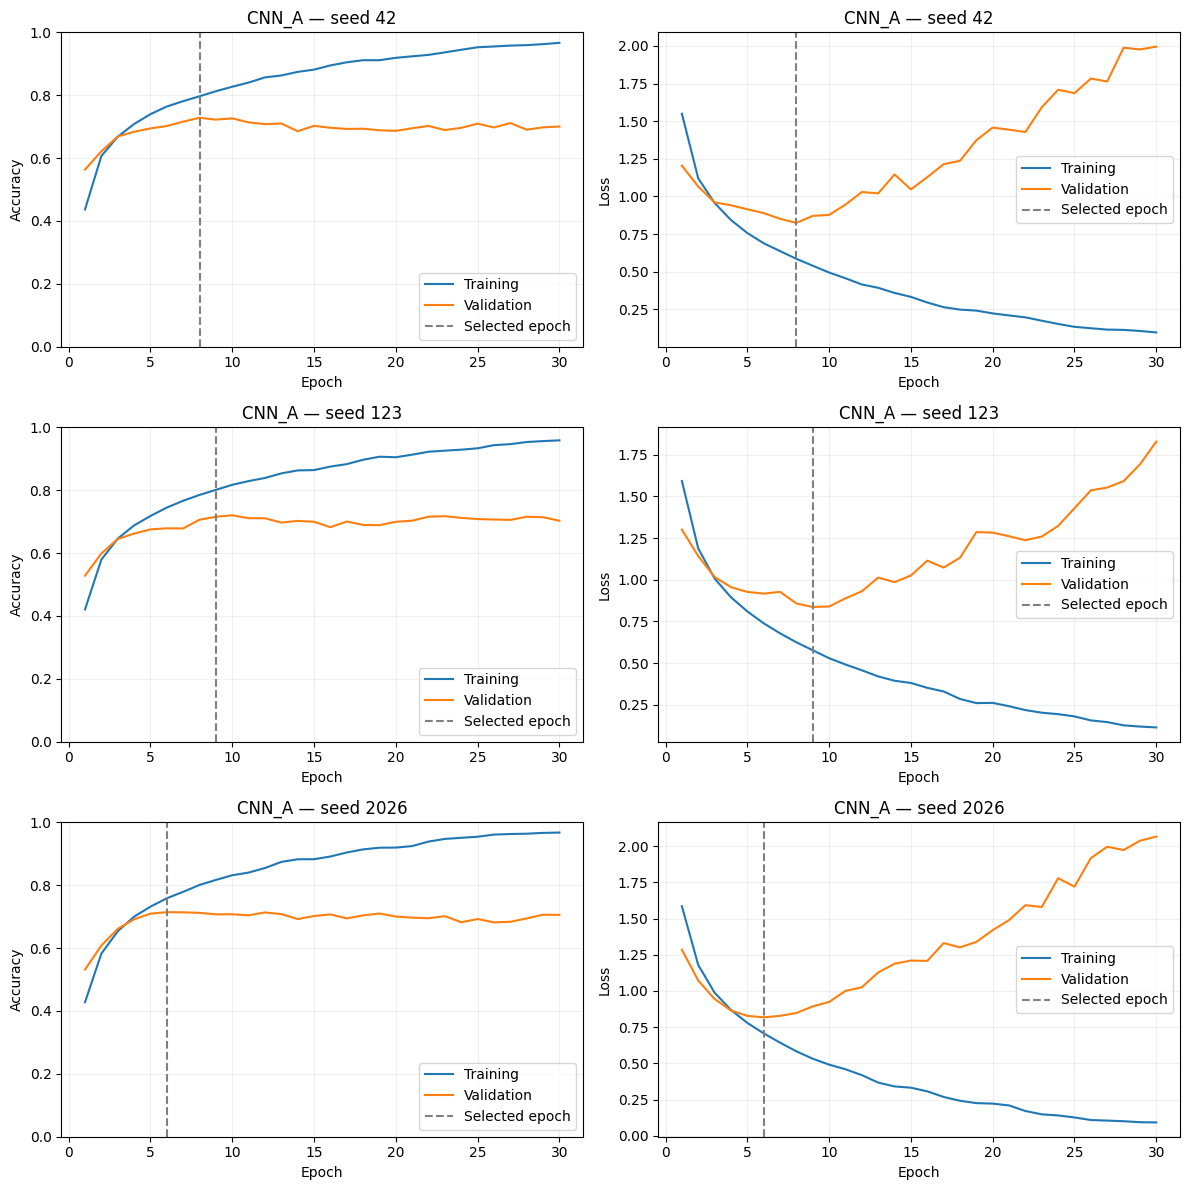

Saved experiment ZIP: /content/assignment3_results/CNN_ABC_zero_one_20261118-220529/CNN_A.zip


In [14]:
all_results["CNN_A"], all_summaries["CNN_A"] = run_experiment("CNN_A")


## 6. 运行 CNN_B

运行此单元格，完成该模型的三个随机种子实验并展示结果和曲线。


Model: "CNN_B"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5 (Conv2D)                  │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv6 (Conv2D)                  │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 2048)           │     8,390,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense2 (Dense)                  │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,644,490 (44.42 MB)

 Trainable params: 11,644,490 (44.42 MB)

 Non-trainable params: 0 (0.00 B)


Training CNN_B: seed=42
Epoch 1/30
352/352 - 10s - 29ms/step - accuracy: 0.3693 - loss: 1.6715 - val_accuracy: 0.5304 - val_loss: 1.2598
Epoch 2/30
352/352 - 7s - 21ms/step - accuracy: 0.6041 - loss: 1.1027 - val_accuracy: 0.6492 - val_loss: 0.9728
Epoch 3/30
352/352 - 7s - 21ms/step - accuracy: 0.7010 - loss: 0.8469 - val_accuracy: 0.7056 - val_loss: 0.8277
Epoch 4/30
352/352 - 7s - 21ms/step - accuracy: 0.7569 - loss: 0.6860 - val_accuracy: 0.7352 - val_loss: 0.7533
Epoch 5/30
352/352 - 7s - 20ms/step - accuracy: 0.7954 - loss: 0.5828 - val_accuracy: 0.7362 - val_loss: 0.7869
Epoch 6/30
352/352 - 7s - 20ms/step - accuracy: 0.8326 - loss: 0.4764 - val_accuracy: 0.7410 - val_loss: 0.8070
Epoch 7/30
352/352 - 7s - 20ms/step - accuracy: 0.8568 - loss: 0.4043 - val_accuracy: 0.7384 - val_loss: 0.8793
Epoch 8/30
352/352 - 7s - 20ms/step - accuracy: 0.8796 - loss: 0.3411 - val_accuracy: 0.7338 - val_loss: 0.9031
Epoch 9/30
352/352 - 7s - 20ms/step - accuracy: 0.9046 - loss: 0.2714 - val_ac

,model,seed,parameters,best_epoch,epochs_run,training_seconds,seconds_per_epoch,train_accuracy,train_loss,val_accuracy,val_loss,test_accuracy,test_loss,train_val_accuracy_gap
0,CNN_B,42,11644490,4,30,215.378364,7.179279,0.796244,0.581765,0.7352,0.753337,0.7352,0.773378,0.061044
1,CNN_B,123,11644490,4,30,215.519104,7.183970,0.782733,0.612978,0.7260,0.789136,0.7181,0.842047,0.056733
2,CNN_B,2026,11644490,4,30,215.859653,7.195322,0.797044,0.570166,0.7296,0.769956,0.7272,0.804408,0.067444


,mean,std
train_accuracy,0.792007,0.008042
train_loss,0.588303,0.022142
val_accuracy,0.730267,0.004636
val_loss,0.770810,0.017915
test_accuracy,0.726833,0.008556
test_loss,0.806611,0.034387
training_seconds,215.585707,0.247460
seconds_per_epoch,7.186190,0.008249
train_val_accuracy_gap,0.061741,0.005389


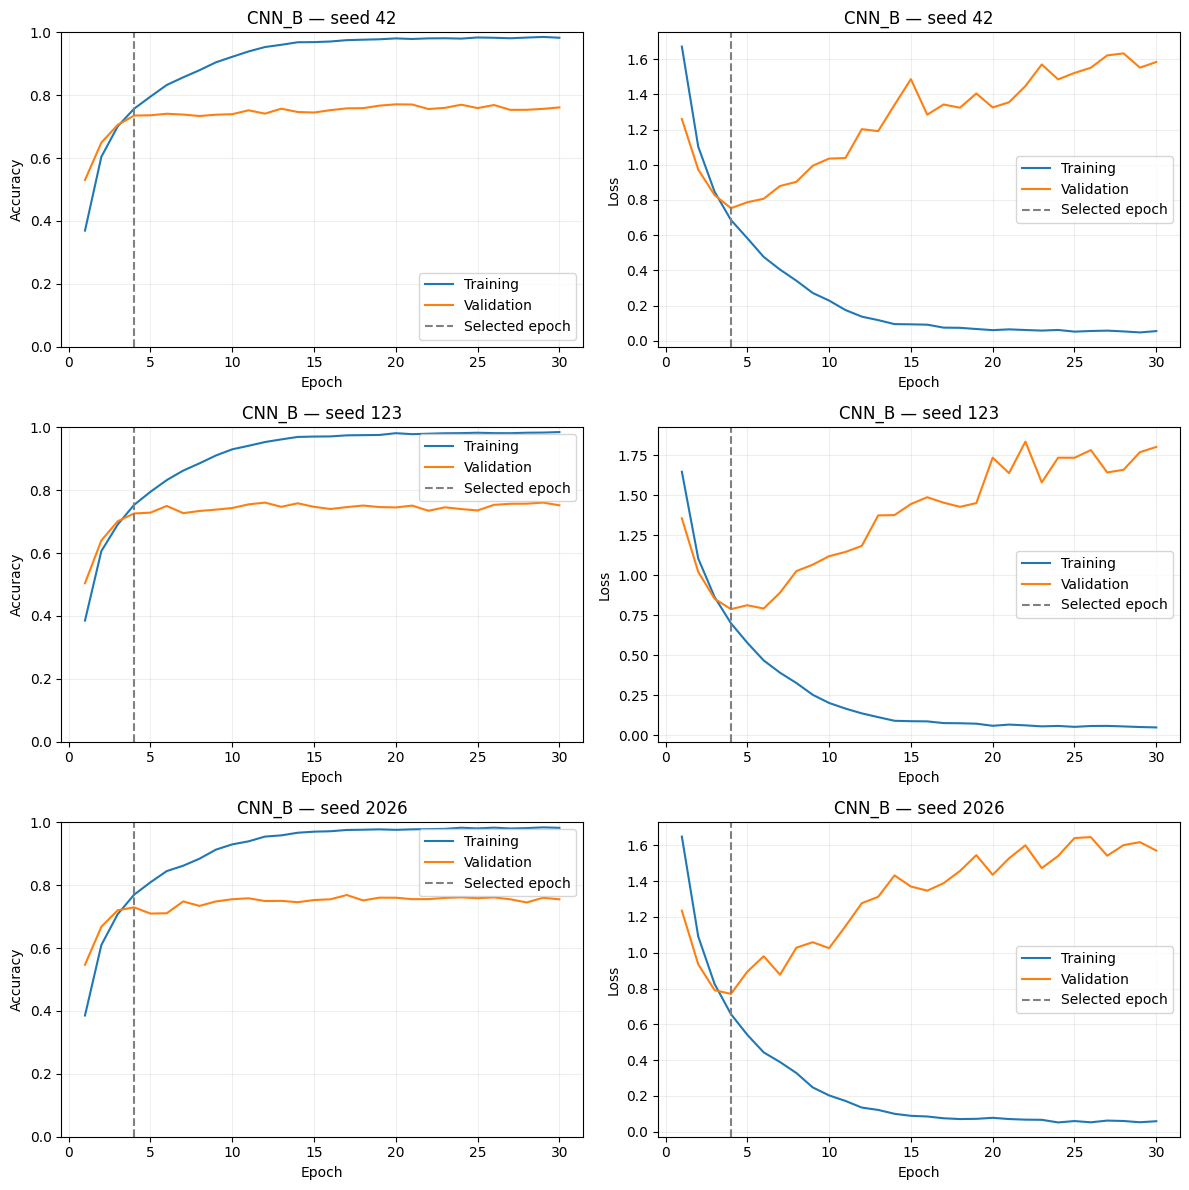

Saved experiment ZIP: /content/assignment3_results/CNN_ABC_zero_one_20261118-220529/CNN_B.zip


In [15]:
all_results["CNN_B"], all_summaries["CNN_B"] = run_experiment("CNN_B")


## 7. 运行 CNN_C

运行此单元格，完成该模型的三个随机种子实验并展示结果和曲线。


,layer,manual_parameters,keras_parameters
0,conv1,864,864
1,bn1,128,128
2,relu1,0,0
3,conv2,9216,9216
4,bn2,128,128
5,relu2,0,0
6,pool1,0,0
7,dropout1,0,0
8,conv3,18432,18432
9,bn3,256,256


Model: "CNN_C"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 32, 32, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 16, 16, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5 (Conv2D)                  │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn5 (BatchNormalization)        │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu5 (Activation)              │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv6 (Conv2D)                  │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn6 (BatchNormalization)        │ (None, 8, 8, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu6 (Activation)              │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout3 (Dropout)              │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             

 Total params: 1,344,106 (5.13 MB)

 Trainable params: 1,342,186 (5.12 MB)

 Non-trainable params: 1,920 (7.50 KB)


Training CNN_C: seed=42
Epoch 1/30
352/352 - 9s - 27ms/step - accuracy: 0.4327 - loss: 1.7452 - val_accuracy: 0.1946 - val_loss: 3.2087
Epoch 2/30
352/352 - 5s - 14ms/step - accuracy: 0.6103 - loss: 1.2334 - val_accuracy: 0.6254 - val_loss: 1.1786
Epoch 3/30
352/352 - 5s - 14ms/step - accuracy: 0.6744 - loss: 1.0594 - val_accuracy: 0.5826 - val_loss: 1.3919
Epoch 4/30
352/352 - 5s - 14ms/step - accuracy: 0.7114 - loss: 0.9578 - val_accuracy: 0.6568 - val_loss: 1.1518
Epoch 5/30
352/352 - 5s - 14ms/step - accuracy: 0.7390 - loss: 0.8901 - val_accuracy: 0.7168 - val_loss: 0.9704
Epoch 6/30
352/352 - 5s - 14ms/step - accuracy: 0.7589 - loss: 0.8405 - val_accuracy: 0.7600 - val_loss: 0.8434
Epoch 7/30
352/352 - 5s - 14ms/step - accuracy: 0.7754 - loss: 0.7999 - val_accuracy: 0.6652 - val_loss: 1.2013
Epoch 8/30
352/352 - 5s - 14ms/step - accuracy: 0.7906 - loss: 0.7681 - val_accuracy: 0.7392 - val_loss: 0.9351
Epoch 9/30
352/352 - 5s - 14ms/step - accuracy: 0.8037 - loss: 0.7373 - val_acc

,model,seed,parameters,best_epoch,epochs_run,training_seconds,seconds_per_epoch,train_accuracy,train_loss,val_accuracy,val_loss,test_accuracy,test_loss,train_val_accuracy_gap
0,CNN_C,42,1344106,19,30,154.632406,5.154414,0.905622,0.521003,0.8358,0.718830,0.8287,0.747852,0.069822
1,CNN_C,123,1344106,18,30,157.479391,5.249313,0.904244,0.513272,0.8396,0.714347,0.8268,0.752088,0.064644
2,CNN_C,2026,1344106,27,30,158.351689,5.278390,0.941644,0.459774,0.8534,0.728788,0.8452,0.743382,0.088244


,mean,std
train_accuracy,0.917170,0.021206
train_loss,0.498016,0.033344
val_accuracy,0.842933,0.009261
val_loss,0.720655,0.007392
test_accuracy,0.833567,0.010119
test_loss,0.747774,0.004354
training_seconds,156.821162,1.945049
seconds_per_epoch,5.227372,0.064835
train_val_accuracy_gap,0.074237,0.012404


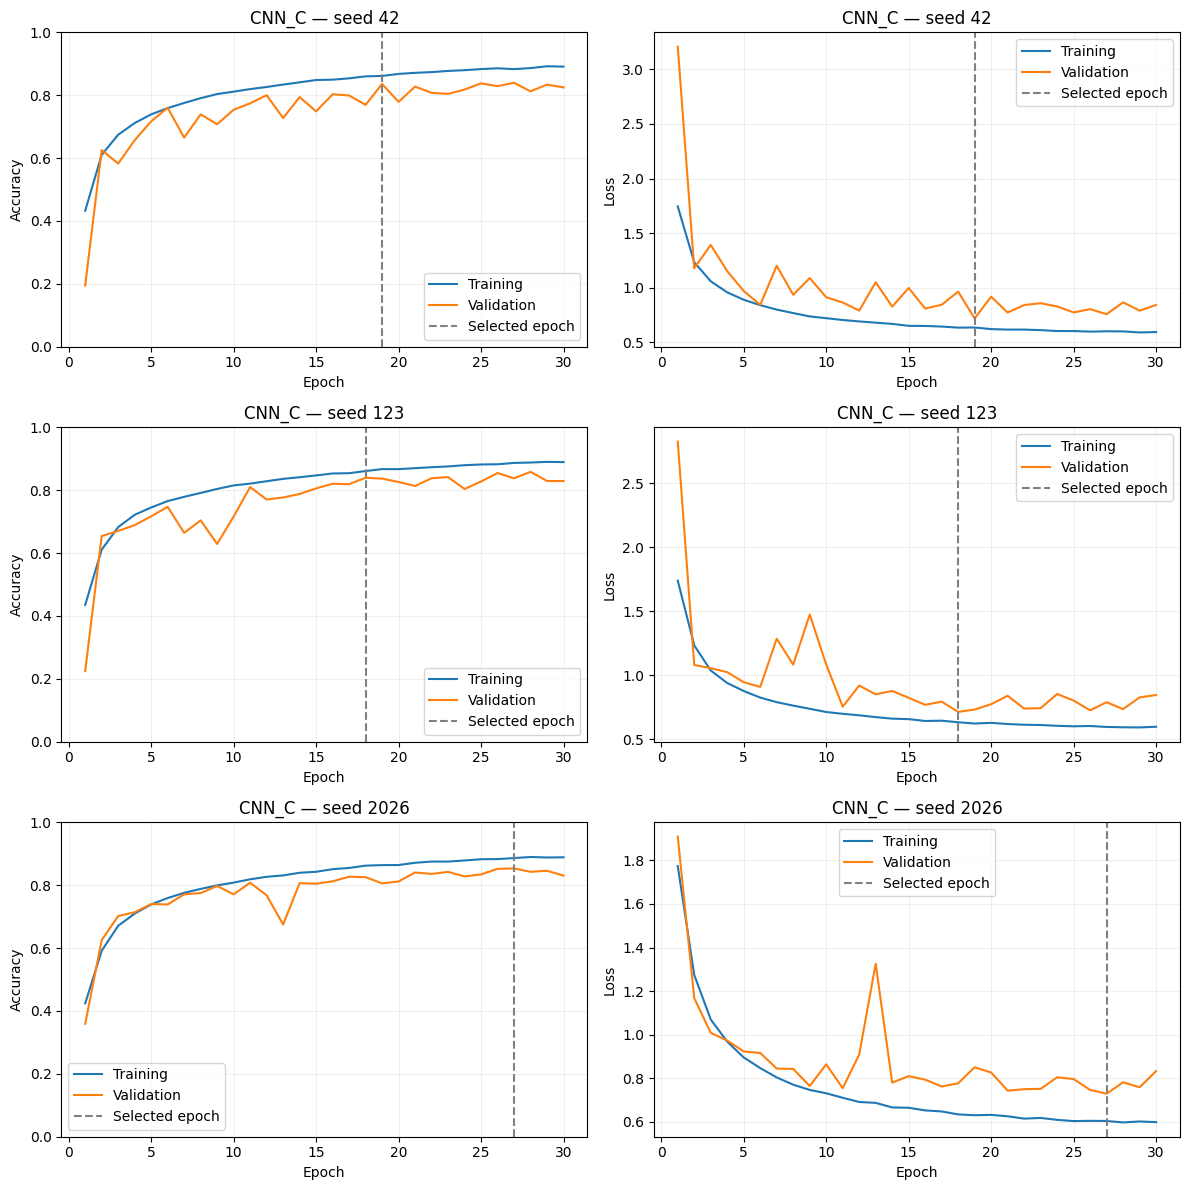

Saved experiment ZIP: /content/assignment3_results/CNN_ABC_zero_one_20261118-220529/CNN_C.zip


In [16]:
all_results["CNN_C"], all_summaries["CNN_C"] = run_experiment("CNN_C")


## 8. 三模型汇总与统一下载
下表使用样本标准差（ddof=1）；准确率乘以 100 后为百分数。仅一个随机种子时标准差无法定义。
CNN_C 的 loss 包含 L2 惩罚项，不能直接与 A／B 的 loss 比较大小。
统一 ZIP 包含三个模型各自的输出及比较表。请下载后再结束 Colab 会话。


In [17]:
required_models = ["CNN_A", "CNN_B", "CNN_C"]
missing = [name for name in required_models if name not in all_results]
assert not missing, f"请先完成这些模型的训练：{missing}"
combined_results = pd.concat([all_results[name] for name in required_models], ignore_index=True)
combined_results.to_csv(EXPERIMENT_DIR / "all_models_results_by_seed.csv", index=False)
comparison_metrics = ["parameters", "train_accuracy", "train_loss", "val_accuracy", "val_loss", "test_accuracy", "test_loss", "train_val_accuracy_gap", "training_seconds", "seconds_per_epoch"]
comparison = combined_results.groupby("model", sort=False)[comparison_metrics].agg(["mean", "std"])
comparison.columns = [f"{metric}_{stat}" for metric, stat in comparison.columns]
comparison.to_csv(EXPERIMENT_DIR / "model_comparison.csv")
display(comparison)
if len(SEEDS) != 3:
    print("当前为快速检查，正式报告需要三个随机种子的结果。")

# 每个模型的 ZIP 已单独保存；统一 ZIP 排除这些重复归档，减少下载体积。
import zipfile
archive = str(EXPERIMENT_DIR) + ".zip"
with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(EXPERIMENT_DIR.rglob("*")):
        if path.is_file() and path.suffix != ".zip":
            bundle.write(path, path.relative_to(EXPERIMENT_DIR))
print("三模型完整结果：", archive)


,parameters_mean,parameters_std,train_accuracy_mean,train_accuracy_std,train_loss_mean,train_loss_std,val_accuracy_mean,val_accuracy_std,val_loss_mean,val_loss_std,test_accuracy_mean,test_accuracy_std,test_loss_mean,test_loss_std,train_val_accuracy_gap_mean,train_val_accuracy_gap_std,training_seconds_mean,training_seconds_std,seconds_per_epoch_mean,seconds_per_epoch_std
model,,,,,,,,,,,,,,,,,,,,
CNN_A,356810.0,0.0,0.798919,0.018242,0.575717,0.054214,0.719333,0.007711,0.826446,0.009684,0.713567,0.006463,0.853768,0.002528,0.079585,0.013376,63.465243,0.414672,2.115508,0.013822
CNN_B,11644490.0,0.0,0.792007,0.008042,0.588303,0.022142,0.730267,0.004636,0.770810,0.017915,0.726833,0.008556,0.806611,0.034387,0.061741,0.005389,215.585707,0.247460,7.186190,0.008249
CNN_C,1344106.0,0.0,0.917170,0.021206,0.498016,0.033344,0.842933,0.009261,0.720655,0.007392,0.833567,0.010119,0.747774,0.004354,0.074237,0.012404,156.821162,1.945049,5.227372,0.064835


三模型完整结果： /content/assignment3_results/CNN_ABC_zero_one_20261118-220529.zip


In [18]:
# 下载包含三个模型结果及比较表的完整 ZIP。
from google.colab import files
files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 报告检查清单 — CNN_A / CNN_B / CNN_C
- 说明模型结构、参数量、优化器、学习率、批次大小、归一化方式和训练轮数。
- 在对应模型的报告页面放入结构图和训练／验证曲线。
- 报告最终测试准确率，以及三个随机种子的均值与标准差，同时记录训练耗时和硬件。
- 说明权重选择规则，并根据实际结果分析过拟合情况。
- 给出 CNN_C 的手算参数量，区分可训练参数和不可训练参数。
- 仍需完成归一化对照实验及完整的六页报告。
